# YOLO26s detector: training process
Three figures from the Ultralytics `results.csv` of the final run. Set `RUN` to plot another run.

In [1]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RUN = os.environ.get("YOLO_1CLS_RUN", "detector_1cls_yolo26s_7")
RUNS = Path("runs")
df = pd.read_csv(RUNS / RUN / "train" / "results.csv")
df.columns = [c.strip() for c in df.columns]
best = int(df["metrics/mAP50(B)"].idxmax())
print(f"{RUN}: {len(df)} epochs, best mAP50 = {df['metrics/mAP50(B)'].max():.3f} at epoch {df['epoch'][best]}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})

detector_1cls_yolo26s_7: 69 epochs, best mAP50 = 0.853 at epoch 44


## Figure 1: Losses
Training and validation box / classification loss fall together, so the model is learning without obvious overfitting. The validation classification loss is noisier than the training one.

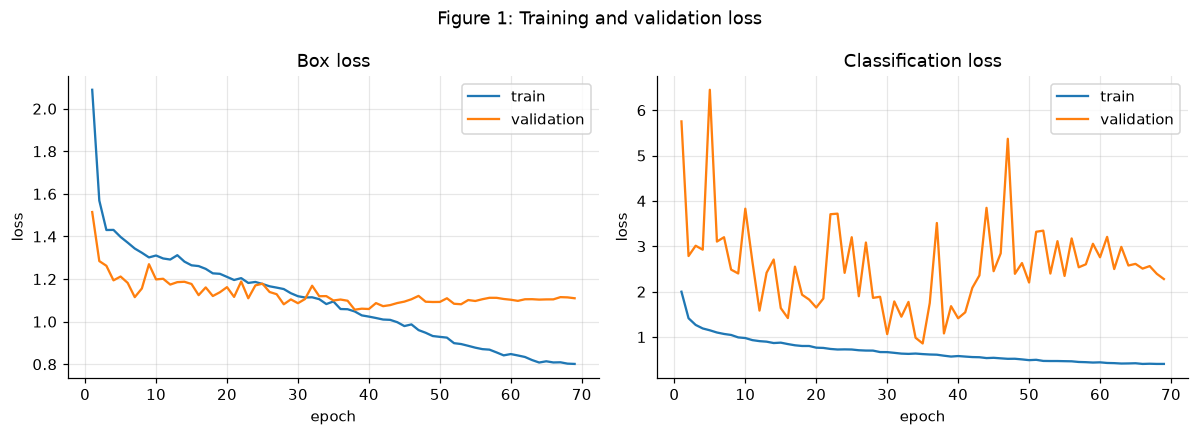

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, k, t in zip(axs, ["box_loss", "cls_loss"], ["Box loss", "Classification loss"]):
    ax.plot(df["epoch"], df[f"train/{k}"], label="train", color="tab:blue")
    ax.plot(df["epoch"], df[f"val/{k}"], label="validation", color="tab:orange")
    ax.set(title=t, xlabel="epoch", ylabel="loss"); ax.legend()
fig.suptitle("Figure 1: Training and validation loss"); fig.tight_layout(); plt.show()

## Figure 2: Validation metrics
mAP, precision and recall on the validation set after every epoch. The dashed line marks the best mAP50 epoch.

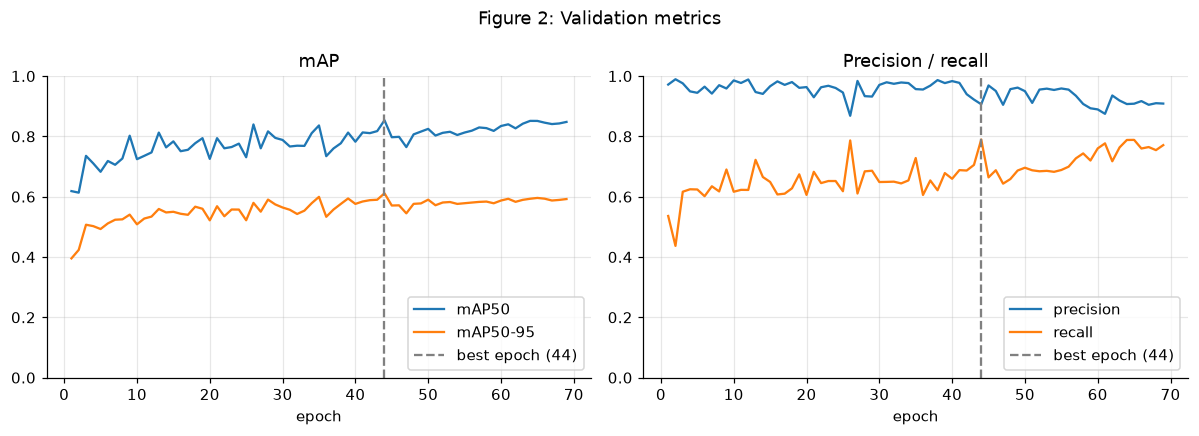

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP50")
axs[0].plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP50-95")
axs[0].set(title="mAP", xlabel="epoch", ylim=(0, 1))
axs[1].plot(df["epoch"], df["metrics/precision(B)"], label="precision")
axs[1].plot(df["epoch"], df["metrics/recall(B)"], label="recall")
axs[1].set(title="Precision / recall", xlabel="epoch", ylim=(0, 1))
for ax in axs:
    ax.axvline(df["epoch"][best], ls="--", color="gray", label=f"best epoch ({df['epoch'][best]})"); ax.legend(loc="lower right")
fig.suptitle("Figure 2: Validation metrics"); fig.tight_layout(); plt.show()

## Figure 3: Learning rate and generalisation gap
The learning-rate schedule (left) and the validation minus training box loss (right), which shows how well the model generalises over time.

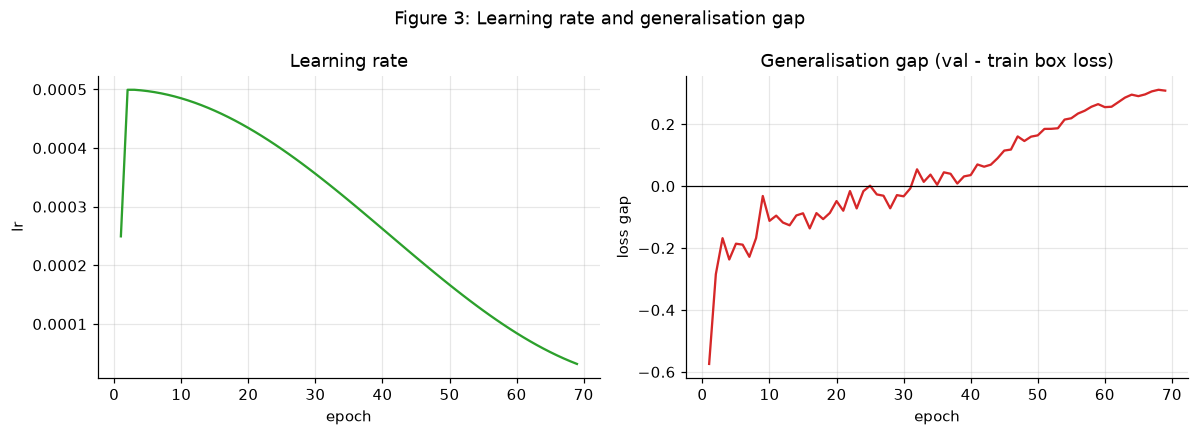

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(df["epoch"], df["lr/pg0"], color="tab:green")
axs[0].set(title="Learning rate", xlabel="epoch", ylabel="lr")
axs[1].plot(df["epoch"], df["val/box_loss"] - df["train/box_loss"], color="tab:red")
axs[1].axhline(0, color="k", lw=.8)
axs[1].set(title="Generalisation gap (val - train box loss)", xlabel="epoch", ylabel="loss gap")
fig.suptitle("Figure 3: Learning rate and generalisation gap"); fig.tight_layout(); plt.show()

# Evaluation report
Results on the frozen synthetic test sets, read from `runs/evaluation/summary.json` (written by `Evaluation.ipynb`). All numbers are on synthetic data; they need confirming on real captures.

In [5]:
import json
import numpy as np
S = json.load(open("runs/evaluation/summary.json"))
best = S["best_pipeline"]
lb = S["leaderboard"][best]
print(f"Best pipeline: {best}")
print(f"  detection F1 {lb['det_f1']:.3f} | class-aware F1 {lb['class_f1']:.3f} | family accuracy on matched boxes {lb['cls_acc_on_matched']:.3f}")

Best pipeline: YOLO-1cls + GBM
  detection F1 0.912 | class-aware F1 0.856 | family accuracy on matched boxes 0.939


## 1. Detection and classification (test set)
A YOLO detector finds the signals, and a gradient-boosting classifier then assigns the modulation family.

,precision,recall,f1
YOLO-1cls,0.902,0.922,0.912


,accuracy,macro_f1,coarse_accuracy,boxes
GBM,0.951,0.951,0.966,3151.0


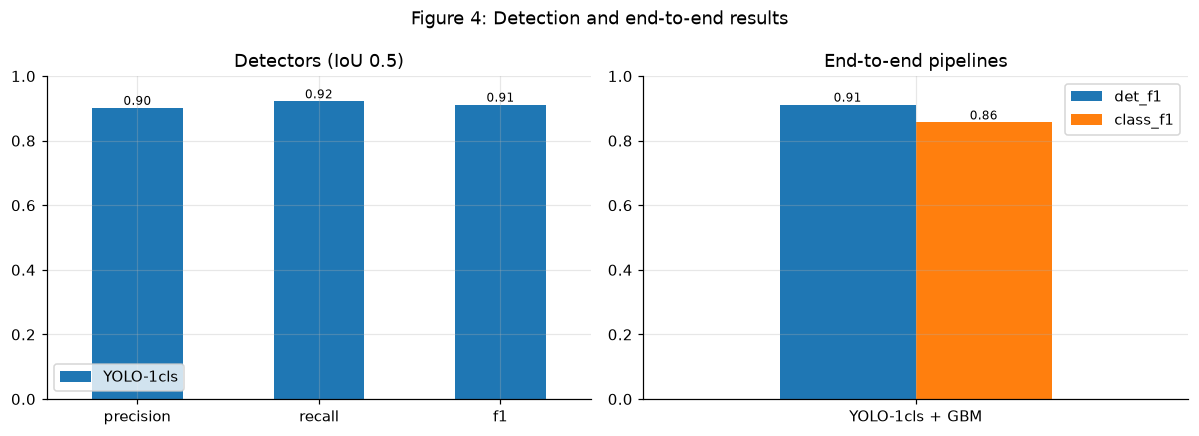

In [6]:
det = pd.DataFrame(S["detectors"]).T[["precision", "recall", "f1"]].drop(index="CFAR")
display(det.round(3))
display(pd.DataFrame(S["classifiers"]).T.round(3))

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
det.T.plot.bar(ax=axs[0], rot=0, ylim=(0, 1)); axs[0].set_title("Detectors (IoU 0.5)")
lbd = pd.DataFrame(S["leaderboard"]).T[["det_f1", "class_f1"]].drop(index="CFAR + GBM")
lbd.plot.bar(ax=axs[1], rot=0, ylim=(0, 1)); axs[1].set_title("End-to-end pipelines")
for ax in axs:
    for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8)
fig.suptitle("Figure 4: Detection and end-to-end results"); fig.tight_layout(); plt.show()

## 2. Robustness to unseen impairments
`test_robust` adds oscillator error, 8-bit ADC and fading, none of which were in training. The classifier degrades mildly, but the detector (and so the full pipeline) loses about 0.2 F1.

,test,test_robust,change
metric,,,
GBM: family accuracy,0.951,0.908,-0.044
YOLO-1cls + GBM (best): class-aware F1,0.856,0.648,-0.208
YOLO-1cls: detection F1,0.912,0.722,-0.190


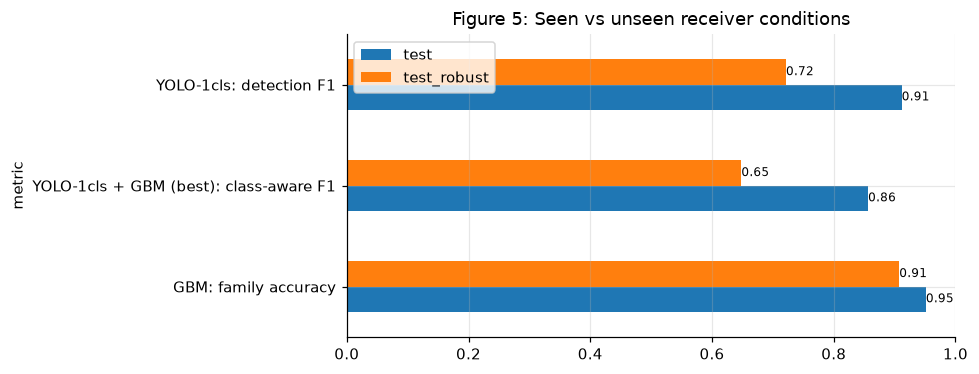

In [7]:
rob = pd.DataFrame(S["robustness"]).set_index("metric")
rob = rob[~rob.index.str.startswith("CFAR")]
display(rob.round(3))
ax = rob[["test", "test_robust"]].plot.barh(figsize=(9, 3.5), xlim=(0, 1))
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8)
ax.set_title("Figure 5: Seen vs unseen receiver conditions"); plt.tight_layout(); plt.show()

## 3. Hard cases: 1 kHz separation and unknown classes

In [8]:
k = pd.DataFrame(S["one_khz"]).T[["success @1 kHz", "merged @1 kHz", "a signal missed @1 kHz"]]
k = k[~k.index.str.startswith("CFAR")]
display(k.round(3))
print("Open-set (signal classes never seen in training):")
display(pd.DataFrame(S["open_set"]).T.round(3))

,success @1 kHz,merged @1 kHz,a signal missed @1 kHz
YOLO-1cls,0.005,0.833,0.162
YOLO-1cls + GBM (class-aware),0.000,0.834,0.166


Open-set (signal classes never seen in training):


,n_known,n_unknown,auroc,fpr_at_95_tpr
GBM (max-softmax),3151.0,1503.0,0.796,0.579


## 4. ROC curves and AUC
One-vs-rest ROC for each modulation family: how well the GBM classifier separates a family from all others on the test set, using ground-truth boxes. Detection has no true negatives, so a ROC does not apply to it; its precision/recall figures are in section 1.

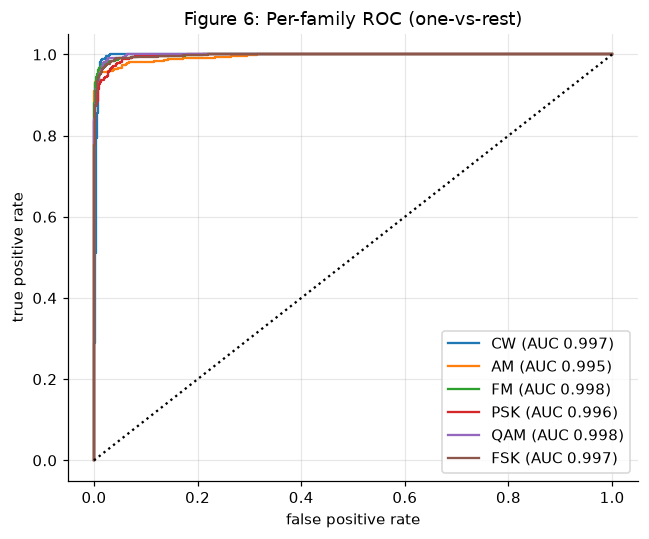

Macro one-vs-rest AUC: 0.997


In [9]:
from sklearn.metrics import roc_curve, roc_auc_score
Z = np.load("runs/evaluation/roc_scores.npz")
FAMILIES = ["CW", "AM", "FM", "PSK", "QAM", "FSK"]
fam, P = Z["GBM_fam_known"], Z["GBM_P_known"]
ok = (fam >= 1) & (fam <= len(FAMILIES))
fam, P = fam[ok], P[ok]

fig, ax = plt.subplots(figsize=(6, 5))
aucs = {}
for j, name in enumerate(FAMILIES):
    y = (fam == j + 1).astype(int)
    fpr, tpr, _ = roc_curve(y, P[:, j]); aucs[name] = roc_auc_score(y, P[:, j])
    ax.plot(fpr, tpr, label=f"{name} (AUC {aucs[name]:.3f})")
ax.plot([0, 1], [0, 1], "k:")
ax.set(title="Figure 6: Per-family ROC (one-vs-rest)", xlabel="false positive rate", ylabel="true positive rate"); ax.legend(loc="lower right")
fig.tight_layout(); plt.show()
print(f"Macro one-vs-rest AUC: {np.mean(list(aucs.values())):.3f}")

## Summary
- **Detection:** YOLO reaches F1 0.91 (precision 0.90, recall 0.92).
- **Classification:** the gradient-boosting classifier gets 95% family accuracy on ground-truth boxes. End to end, the best pipeline (YOLO + GBM) reaches class-aware F1 0.86.
- **Robustness:** unseen impairments cost the full pipeline about 0.21 F1, mainly through the detector.
- **Known weakness, 1 kHz separation:** the pipeline does not separate two signals 1 kHz apart (success about 0%). YOLO merges them into one box in 83% of scenes and misses a signal in a further 16%.
- **Open set:** unknown classes are only moderately separable (AUROC 0.80, FPR 58% at 95% TPR).
- **ROC per family:** one-vs-rest AUC is about 0.997 on average (Figure 6).
- **Caveat:** everything is measured on synthetic data, so confirm on real captures.